<a href="https://colab.research.google.com/github/jyryu3161/2026CADD/blob/main/week6_LBVS_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 실습: Molfeat 기반 Ligand-Based Virtual Screening과 앙상블 비교

**표적:** Adenosine A2A receptor (AA2AR, GPCR)

이 실습에서는 **같은 분자 라이브러리를 여러 표현법으로 검색**하고, 단일 방법과 앙상블의 **Hit Rate, EF1%, AUROC, Scaffold Diversity**를 비교합니다.

학습 목표
1. Active, Decoy, Query ligand 및 Screening library의 차이를 설명한다.
2. ECFP4, USRCAT, ElectroShape가 표현하는 분자 정보의 차이를 이해한다.
3. 유사도를 사용해 화합물을 정렬하고 상위 후보를 선정한다.
4. 여러 순위를 결합하는 Ensemble 전략(RRF, 평균 백분위 순위, Hit-list Union)을 구현한다.
5. 결과 지표를 계산하고 앙상블이 항상 더 좋은 것은 아니라는 사실을 확인한다.


## 1. 이론: LBVS, Active, Decoy

**Ligand-Based Virtual Screening (LBVS)**은 이미 활성이 알려진 분자(**Query ligand**)와 비슷한 분자를 라이브러리에서 찾는 방법입니다. 수용체의 구조를 반드시 알아야 하는 것은 아닙니다.

| 개념 | 정의 | 이 실습의 역할 |
|---|---|---|
| Active | 표적에 대한 활성이 알려진 화합물 | `label=1` |
| Decoy | Active와 분자량·소수성 등은 유사하게 맞추되 2D 구조는 달라지도록 선택한 비교용 화합물 | `label=0` |
| Query ligand | 비교의 기준이 되는 알려진 활성 화합물 | 데이터에서 **미리 제외** |
| Screening library | 실제로 유사도 점수를 매길 후보 집합 | 남은 Active + Decoy |

### Decoy는 '실험으로 비활성이 확인된 물질'인가?

**아닙니다.** DUD-E Decoy는 *대부분 계산적으로 선정된 추정 음성(putative negative)*입니다. 일부가 실제로 활성을 나타낼 가능성이 있고, Active와 Decoy를 만드는 규칙 자체에서 **benchmark bias**가 발생할 수 있습니다. 따라서 아래의 `Hit Rate`는 **DUD-E 정답(label) 기준의 Hit Rate**이며 실제 실험 성공률이 아닙니다.

**질문:** Active가 400개, Decoy가 4,600개라면 무작위로 100개를 고를 때 Active는 평균 몇 개일까요? (정답: 8개)

## 2. 이론: 세 가지 분자 표현과 Ensemble

- **ECFP4:** 2D 연결 구조를 2048-bit fingerprint로 표현하며, **Tanimoto similarity**로 비교합니다. (Morgan radius=2)
- **USRCAT:** 3D 분자 형태(shape)와 원자 유형·pharmacophoric 특징을 수치 벡터로 표현합니다. **3D 중첩 정렬 없이** 빠르게 비교합니다.
- **ElectroShape:** 분자의 3D 형태, 전하 정보, chirality 등의 특성을 descriptor로 계산합니다. 이 실습에서는 **평균 절대거리(L1)를 유사도 형태로 변환하는 교육용 랭킹**을 사용합니다. 이는 원논문의 정식 ElectroShape scoring function과 동일하다고 주장하지 않습니다.

**Ensemble:** 독립 방법이 예측한 **순위**를 합쳐 최종 순위를 만듭니다. 서로 다른 점수 척도를 그대로 더하지 않고 순위를 합치는 이유도 살펴봅니다.

**공정한 비교:** 모든 방법에서 **동일한 평가 화합물**을 사용하고 동일한 Top 1% 예산으로 hit를 비교합니다.

## 3. 라이브러리 설치

Colab에서는 일반적으로 `condacolab` 없이 pip 설치만으로 충분합니다. 첫 실행 시 설치에 1~3분 정도 소요될 수 있습니다. 설치 오류가 발생하면 런타임을 다시 시작하고 다음 셀부터 재실행하세요.

In [23]:
%pip -q install molfeat rdkit numpy pandas scikit-learn matplotlib tqdm requests

## 4. 기본 설정과 라이브러리 불러오기

- **MAX_DECOYS=2000:** 강의 시간에 맞춰 Decoy 2,000개 사용. 더 정확한 검증을 위해 5,000개 또는 `None`(전체)으로 변경할 수 있습니다.
- **N_QUERY=5:** 활성이 알려진 분자 5개를 기준 분자로 사용합니다.
- **TOP_FRACTION=0.01:** 상위 1%에서 hit를 평가합니다.
- **SEED=42:** 매번 같은 샘플을 선택하도록 설정합니다.

처음에는 `MAX_DECOYS=500`으로 전체 흐름을 익힌 후 2,000개로 늘려도 됩니다.

In [24]:
import io
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from IPython.display import display
from rdkit import Chem
from rdkit import DataStructs
from rdkit import RDLogger
from rdkit.Chem import AllChem
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.metrics import roc_auc_score, roc_curve
from molfeat.calc.shape import USRDescriptors, ElectroShapeDescriptors

RDLogger.DisableLog("rdApp.*")

SEED = 42
MAX_DECOYS = 1000
N_QUERY = 5
TOP_FRACTION = 0.01

print("라이브러리를 불러왔습니다.")

라이브러리를 불러왔습니다.


## 5. DUD-E AA2AR 데이터 다운로드

공식 데이터: https://dude.docking.org/targets/aa2ar

AA2AR은 Adenosine A2A receptor로, DUD-E에서 자주 사용되는 GPCR 표적입니다.

파일 구조는 보통 **SMILES + 화합물 ID**입니다. 문자열을 읽어 RDKit이 인식하는 분자만 남깁니다. Active와 Decoy에 같은 SMILES가 들어 있다면 평가에서 제외합니다.

> 외부 서버 접속이 필요한 셀입니다. 다운로드 실패 시 네트워크 상태나 DUD-E 사이트 접근 가능 여부를 확인하세요.

In [25]:
BASE_URL = "https://dude.docking.org/targets/aa2ar"

def load_dude_file(file_name, label):
    url = BASE_URL + "/" + file_name
    response = requests.get(url, timeout=120)
    response.raise_for_status()

    records = []
    for line in response.text.splitlines():
        items = line.strip().split()
        if len(items) == 0:
            continue
        if items[0].startswith("#"):
            continue

        mol = Chem.MolFromSmiles(items[0])
        if mol is None:
            continue

        smiles = Chem.MolToSmiles(mol, isomericSmiles=True)
        if len(items) >= 2:
            compound_id = items[1]
        else:
            compound_id = "compound_" + str(len(records))

        records.append([smiles, compound_id, label])

    df = pd.DataFrame(records, columns=["smiles", "compound_id", "label"])
    return df

actives = load_dude_file("actives_final.ism", 1)
decoys = load_dude_file("decoys_final.ism", 0)

print("원본 Active:", len(actives))
print("원본 Decoy:", len(decoys))
display(actives.head())

원본 Active: 482
원본 Decoy: 31550


,smiles,compound_id,label
0,C#CCOc1nc(-c2ccccc2)nc2sc3c(c12)CCC3,630004,1
1,O=S(=O)(O)CCNc1ncnc2c1ncn2C1O[C@H](CO)[C@@H](O...,607385,1
2,CCNC(=O)[C@H]1OC(n2cnc3c(N)nc(C#Cc4ccc(CCC(=O)...,605505,1
3,S=c1sc2c(ncn3nc(-c4ccco4)nc23)n1-c1cccc(I)c1,623098,1
4,C=CCn1c(=S)sc2c1ncn1nc(-c3ccco3)nc21,623027,1


## 6. 화합물 중복 제거 및 실습용 데이터 선택

최종 데이터셋에서 동일한 분자가 서로 다른 정답(label)을 갖는 문제를 방지합니다. 이후 강의 속도를 위해 Decoy 일부를 고정된 난수로 추출합니다.

**주의:** Decoy 수를 변경하면 Active 비율(prevalence)이 변하므로 **Hit Rate의 절대값도 변할 수 있습니다.** 따라서 서로 다른 Decoy 설정의 결과를 직접 비교하지 않습니다.

In [26]:
all_compounds = pd.concat([actives, decoys], ignore_index=True)

# 같은 SMILES가 Active, Decoy 양쪽에 존재하는 경우를 찾습니다.
label_count = all_compounds.groupby("smiles")["label"].nunique()
conflicting_smiles = label_count[label_count > 1].index
all_compounds = all_compounds[~all_compounds["smiles"].isin(conflicting_smiles)]

# 같은 SMILES는 하나의 분자로 취급합니다.
all_compounds = all_compounds.drop_duplicates(subset="smiles", keep="first")

actives = all_compounds[all_compounds["label"] == 1].copy()
decoys = all_compounds[all_compounds["label"] == 0].copy()

if MAX_DECOYS is not None:
    sample_size = min(MAX_DECOYS, len(decoys))
    decoys = decoys.sample(n=sample_size, random_state=SEED)

actives = actives.reset_index(drop=True)
decoys = decoys.reset_index(drop=True)

print("정리된 Active:", len(actives))
print("실습용 Decoy:", len(decoys))

정리된 Active: 482
실습용 Decoy: 1000


## 7. Query ligand와 평가 데이터를 분리하기

**Query ligand가 평가 라이브러리에 들어 있으면 자기 자신과의 similarity=1이 되어 성능이 과대평가됩니다.** 이를 막기 위해 Active 중 5개를 Query로 선택하고, 나머지만 평가합니다.

첫 Query는 첫 번째 Active로 정하고, 그다음은 기존 Query들과 2D Tanimoto similarity가 가장 낮은 Active를 차례대로 선택합니다. 따라서 여러 chemotype을 검색 기준에 포함하려는 간단한 **diversity selection**입니다.

**주의:** 이는 엄밀한 scaffold split이 아닙니다. 쿼리 분리와 scaffold generalization 검증은 서로 다릅니다.

In [27]:
fp_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

active_fps = []
for smiles in actives["smiles"]:
    mol = Chem.MolFromSmiles(smiles)
    fp = fp_generator.GetFingerprint(mol)
    active_fps.append(fp)

selected_indices = [0]

while len(selected_indices) < min(N_QUERY, len(actives)):
    best_index = None
    lowest_max_similarity = 2.0

    for candidate_index in range(len(actives)):
        if candidate_index in selected_indices:
            continue

        # 후보가 기존 Query 중 어느 것과 가장 닮았는지 확인합니다.
        max_similarity = 0.0
        for query_index in selected_indices:
            similarity = DataStructs.TanimotoSimilarity(
                active_fps[candidate_index], active_fps[query_index]
            )
            if similarity > max_similarity:
                max_similarity = similarity

        # 기존 Query와 가장 덜 닮은 후보를 새 Query로 선택합니다.
        if max_similarity < lowest_max_similarity:
            lowest_max_similarity = max_similarity
            best_index = candidate_index

    selected_indices.append(best_index)

queries = actives.iloc[selected_indices].copy()
evaluation_actives = actives.drop(index=selected_indices)

screen = pd.concat([evaluation_actives, decoys], ignore_index=True)
screen = screen.sample(frac=1, random_state=SEED)
screen = screen.reset_index(drop=True)
queries = queries.reset_index(drop=True)

print("Query 수:", len(queries))
print("평가 라이브러리 크기:", len(screen))
print("평가 Active 수:", int(screen["label"].sum()))
print("Active 비율:", round(screen["label"].mean(), 4))
display(queries)

Query 수: 5
평가 라이브러리 크기: 1477
평가 Active 수: 477
Active 비율: 0.323


,smiles,compound_id,label
0,C#CCOc1nc(-c2ccccc2)nc2sc3c(c12)CCC3,630004,1
1,CCCn1c(=O)c2nc(CCCNC(=O)CBr)[nH]c2n(CCC)c1=O,148783,1
2,Nc1nc(-c2ccco2)c2nnn(Cc3ccc4[nH]ccc4c3)c2n1,472437,1
3,Cc1csc(-c2nc(N(C)C)nc3ccsc23)n1,427600,1
4,O=[N+]([O-])c1ccc(O)c(/C=N/N=C(\S)Cc2ccccc2)c1,279811,1


### Query ligand의 2D 구조 확인

선택한 5개 Query가 실제로 어떤 화학 구조인지 살펴봅니다.

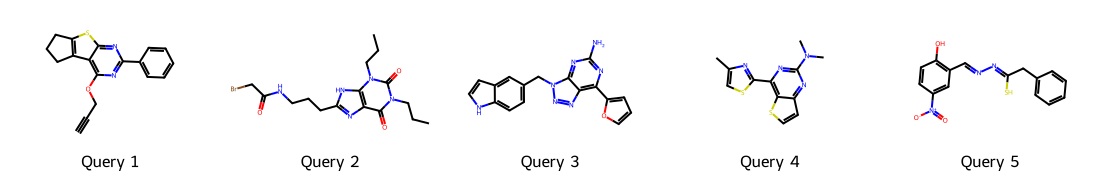

In [45]:
query_molecules = []
query_labels = []

for i in range(len(queries)):
    mol = Chem.MolFromSmiles(queries.loc[i, "smiles"])
    query_molecules.append(mol)
    query_labels.append("Query " + str(i + 1))

query_image = Draw.MolsToGridImage(
    query_molecules, molsPerRow=5, subImgSize=(220, 180), legends=query_labels
)
display(query_image)

## 8. 3D Conformer란 무엇인가?

SMILES는 분자의 **원자 연결 관계**를 나타내지만 3D 좌표를 직접 제공하지 않습니다. 회전 가능한 결합 때문에 하나의 분자는 여러 형태(**conformer**)를 가질 수 있습니다.

- **ETKDG:** RDKit의 3D 좌표 생성 알고리즘
- **MMFF94:** 분자의 에너지를 낮추도록 3D 구조를 최적화하는 분자역학 force field
- **Conformer sampling:** 여러 3D 구조를 만들면 3D similarity가 달라질 수 있음

이번 실습은 계산량을 줄이기 위해 **분자당 1개 conformer**만 생성합니다. 이 구조가 실제 결합 상태라는 보장은 없습니다.

아래 코드는 3D 좌표를 만들고 최적화합니다. 실패한 분자는 **모든 방법의 공정한 비교를 위해 함께 제외**합니다.

In [46]:
def create_3d_molecule(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    mol = Chem.AddHs(mol)
    parameters = AllChem.ETKDGv3()
    parameters.randomSeed = SEED
    parameters.maxIterations = 100

    status = AllChem.EmbedMolecule(mol, parameters)
    if status != 0:
        return None

    try:
        if AllChem.MMFFHasAllMoleculeParams(mol):
            AllChem.MMFFOptimizeMolecule(mol, maxIters=100)
        else:
            AllChem.UFFOptimizeMolecule(mol, maxIters=100)
    except Exception:
        return None

    return mol

example_smiles = queries.loc[0, "smiles"]
example_mol3d = create_3d_molecule(example_smiles)

print("3D 생성 성공:", example_mol3d is not None)
if example_mol3d is not None:
    print("Conformer 개수:", example_mol3d.GetNumConformers())

3D 생성 성공: True
Conformer 개수: 1


## 9. Molfeat으로 3D Descriptor 계산하기

세 가지 특징을 **같은 화합물**에서 추출합니다.

1. **ECFP4**: RDKit을 사용한 2D fingerprint
2. **USRCAT**: Molfeat의 `USRDescriptors`
3. **ElectroShape**: Molfeat의 `ElectroShapeDescriptors`

Molfeat이 계산한 것은 **분자의 벡터 표현(descriptor)**입니다. Screening score를 계산하려면 별도 similarity 함수를 적용해야 합니다.

> 분자당 3D 생성이 오래 걸릴 수 있습니다. `MAX_DECOYS=2000`이면 Colab CPU에서 수분 이상 소요될 수 있습니다.

In [30]:
usrcat_calculator = USRDescriptors(method="USRCAT")
electro_calculator = ElectroShapeDescriptors(charge_model="gasteiger")

def calculate_features(smiles):
    mol_2d = Chem.MolFromSmiles(smiles)
    mol_3d = create_3d_molecule(smiles)
    if mol_2d is None or mol_3d is None:
        return None

    try:
        ecfp = fp_generator.GetFingerprint(mol_2d)
        usrcat = np.asarray(usrcat_calculator(mol_3d), dtype=float)
        electro = np.asarray(electro_calculator(mol_3d), dtype=float)

        if not np.all(np.isfinite(usrcat)):
            return None
        if not np.all(np.isfinite(electro)):
            return None

        return {"ecfp": ecfp, "usrcat": usrcat, "electro": electro}
    except Exception:
        return None

start_time = time.time()

query_features = []
valid_query_rows = []
for i in tqdm(range(len(queries)), desc="Query descriptor"):
    feature = calculate_features(queries.loc[i, "smiles"])
    if feature is not None:
        query_features.append(feature)
        valid_query_rows.append(i)

screen_features = []
valid_screen_rows = []
for i in tqdm(range(len(screen)), desc="Library descriptor"):
    feature = calculate_features(screen.loc[i, "smiles"])
    if feature is not None:
        screen_features.append(feature)
        valid_screen_rows.append(i)

queries = queries.iloc[valid_query_rows].reset_index(drop=True)
screen = screen.iloc[valid_screen_rows].reset_index(drop=True)

if len(query_features) == 0:
    raise ValueError("Query descriptor 계산이 모두 실패했습니다.")
if screen["label"].nunique() != 2:
    raise ValueError("최종 라이브러리에 Active와 Decoy가 모두 필요합니다.")

elapsed = (time.time() - start_time) / 60
print("성공한 Query:", len(queries))
print("성공한 평가 분자:", len(screen))
print("실행시간(분):", round(elapsed, 2))

Query descriptor:   0%|          | 0/5 [00:00<?, ?it/s]

Library descriptor:   0%|          | 0/1477 [00:00<?, ?it/s]

성공한 Query: 5
성공한 평가 분자: 1476
실행시간(분): 3.74


## 10. 단일 방법 ① ECFP4 + Tanimoto

ECFP4는 활성 ligand와 원자 연결 패턴이 비슷한 분자를 찾습니다.

\[ T(A,B)=\frac{|A\cap B|}{|A\cup B|} \]

여러 Query가 있을 때 **가장 유사한 Query의 점수(maximum similarity)**를 사용합니다. 이후 3D 방법에도 동일한 규칙을 적용합니다.

In [48]:
query_ecfp = []
for feature in query_features:
    query_ecfp.append(feature["ecfp"])

scores_ecfp = []
for feature in tqdm(screen_features, desc="ECFP4 검색"):
    current_fp = feature["ecfp"]
    similarities = DataStructs.BulkTanimotoSimilarity(current_fp, query_ecfp)
    best_similarity = max(similarities)
    scores_ecfp.append(best_similarity)

results = screen.copy()
results["ECFP4"] = scores_ecfp
print("ECFP4 계산 완료")

ECFP4 검색:   0%|          | 0/1476 [00:00<?, ?it/s]

ECFP4 계산 완료


## 11. 단일 방법 ② USRCAT

USRCAT은 3D Shape와 Pharmacophoric 원자 특징을 결합합니다. RDKit의 `GetUSRScore()`를 이용해 두 USRCAT descriptor 간 similarity를 계산합니다.

**주의:** 이 방법은 shape overlay나 docking을 수행하지 않습니다. Descriptor끼리 비교합니다.

In [50]:
query_usrcat = []
for feature in query_features:
    query_usrcat.append(feature["usrcat"].tolist())

scores_usrcat = []
for feature in tqdm(screen_features, desc="USRCAT 검색"):
    current_vector = feature["usrcat"].tolist()
    best_similarity = 0.0

    for query_vector in query_usrcat:
        similarity = rdMolDescriptors.GetUSRScore(current_vector, query_vector)
        if similarity > best_similarity:
            best_similarity = similarity

    scores_usrcat.append(best_similarity)

results["USRCAT"] = scores_usrcat
print("USRCAT 계산 완료")

USRCAT 검색:   0%|          | 0/1476 [00:00<?, ?it/s]

USRCAT 계산 완료


## 12. 단일 방법 ③ ElectroShape

ElectroShape는 3D 기하학과 전기적 특성을 반영합니다. 각 좌표의 차이를 계산한 뒤 평균 절대거리(**mean absolute distance**)를 구합니다.

\[d(A,B)=\mathrm{mean}(|A-B|),\qquad S=\frac{1}{1+d}\]

값이 **1에 가까울수록 유사**합니다. 이는 교육용으로 선택한 **거리 기반 랭킹**이며 공식 ElectroShape 유사도 정의와 동일한 구현은 아닙니다. 전하 모델·protonation state에 따라 결과가 달라질 수 있습니다.

In [51]:
query_electro = []
for feature in query_features:
    query_electro.append(feature["electro"])

scores_electro = []
for feature in tqdm(screen_features, desc="ElectroShape 검색"):
    current_vector = feature["electro"]
    smallest_distance = float("inf")

    for query_vector in query_electro:
        differences = np.abs(current_vector - query_vector)
        distance = np.mean(differences)

        if distance < smallest_distance:
            smallest_distance = distance

    similarity = 1.0 / (1.0 + smallest_distance)
    scores_electro.append(similarity)

results["ElectroShape"] = scores_electro
print("ElectroShape 계산 완료")
display(results[["compound_id", "label", "ECFP4", "USRCAT", "ElectroShape"]].head())

ElectroShape 검색:   0%|          | 0/1476 [00:00<?, ?it/s]

ElectroShape 계산 완료


,compound_id,label,ECFP4,USRCAT,ElectroShape
0,C35736704,0,0.097222,0.209271,0.668276
1,C20830994,0,0.113402,0.099741,0.482142
2,C16700819,0,0.094595,0.206511,0.588193
3,606919,1,0.182796,0.128910,0.540177
4,567046,1,0.291667,0.240070,0.652298


## 13. Ensemble 방법 ① RRF (Reciprocal Rank Fusion)

ECFP4와 USRCAT의 점수 범위·분포는 다를 수 있습니다. 원점수를 단순 평균하지 않고 **각 점수의 순위**를 결합합니다.

\[\mathrm{RRF}(c)=\sum_{m=1}^{M}\frac{1}{k+r_m(c)}\]

여기서 `r_m(c)`는 방법 `m`에서 화합물 `c`의 순위(1이 최고)이고, `k=60`은 순위 차이를 부드럽게 만드는 상수입니다. RRF 점수가 높은 화합물이 상위권입니다.

In [52]:
methods = ["ECFP4", "USRCAT", "ElectroShape"]

for method in methods:
    rank_column = method + "_rank"
    results[rank_column] = results[method].rank(
        ascending=False, method="average"
    )

results["Ensemble_RRF"] = 0.0

for method in methods:
    rank_column = method + "_rank"
    contribution = 1.0 / (60.0 + results[rank_column])
    results["Ensemble_RRF"] = results["Ensemble_RRF"] + contribution

print("RRF 점수 계산 완료")

RRF 점수 계산 완료


## 14. Ensemble 방법 ② 평균 백분위 순위

순위가 같은 척도(전체 라이브러리 크기 `N`)가 되도록 변환하고 평균을 냅니다.

\[ P_m(c)=\frac{N-r_m(c)}{N},\qquad \mathrm{MeanRank}(c)=\frac{1}{M}\sum_m P_m(c) \]

원점수 평균(score fusion)과는 다르며, 각 방법이 매긴 순위의 상대적인 위치를 결합합니다.

In [54]:
number_of_compounds = len(results)
results["Ensemble_RankMean"] = 0.0

for method in methods:
    rank_column = method + "_rank"
    percentile_score = (number_of_compounds - results[rank_column]) / number_of_compounds
    results["Ensemble_RankMean"] = results["Ensemble_RankMean"] + percentile_score

results["Ensemble_RankMean"] = results["Ensemble_RankMean"] / len(methods)
print("평균 백분위 순위 계산 완료")
results

평균 백분위 순위 계산 완료


,smiles,compound_id,label,ECFP4,ElectroShape,USRCAT,ECFP4_rank,USRCAT_rank,ElectroShape_rank,Ensemble_RRF,Ensemble_RankMean
0,C[C@H](Nc1cc2c(cc1N)NC(=O)CC2)c1cccs1,C35736704,0,0.097222,0.668276,0.209271,1313.5,449.0,441.0,0.004689,0.502371
1,C=CCn1c(CNc2cccc3ccccc23)nnc1SCCC(=O)Nc1ccc(S(...,C20830994,0,0.113402,0.482142,0.099741,1068.0,1455.0,1252.0,0.002309,0.147471
2,Cc1cc(N2C(=O)[C@H](C)CS2(=O)=O)ccc1S(=O)(=O)NC...,C16700819,0,0.094595,0.588193,0.206511,1340.0,481.0,842.0,0.003671,0.398600
3,Nc1nc(N/N=C/C=C/c2ccc([N+](=O)[O-])cc2)nc2c1nc...,606919,1,0.182796,0.540177,0.128910,365.5,1383.0,1039.0,0.003953,0.370483
4,Nc1nc(C(=O)NCc2ccco2)cc(-c2ccco2)n1,567046,1,0.291667,0.652298,0.240070,58.0,192.0,519.0,0.014170,0.826332
...,...,...,...,...,...,...,...,...,...,...,...
1471,CCC(=O)N1CCc2cc(C(=O)NNC(=O)c3ccc(C)cc3C)ccc21,C44820709,0,0.107143,0.452522,0.215585,1173.0,381.0,1336.0,0.003795,0.347335
1472,Nc1cc(C(=O)NC[C@H]2CCCOC2)c([N+](=O)[O-])cc1F,C50708866,0,0.150000,0.673490,0.185075,568.5,819.0,419.0,0.004816,0.592028
1473,O=c1[nH]c2ccccc2n1C1CC[NH+](C[C@@H](O)[C@H]2CO...,C01869697,0,0.118280,0.622087,0.187323,971.0,783.0,674.0,0.003519,0.451671
1474,C[C@@H]1c2cccc(O)c2C[C@@H]2C(=O)[C@@]3(O)C([O-...,C35044610,0,0.108696,0.262600,0.161251,1139.5,1147.0,1470.0,0.002316,0.151649


## 15. Ensemble 방법 ③ Hit-list Union + RRF

각 단일 방법에서 **상위 `ceil(K/3)`개**를 고른 뒤 합집합을 만듭니다. 중복 제거 후 `K`개보다 적으면 RRF 상위 후보로 채웁니다. 이것은 **다양한 추천 경로를 확보하려는 heuristic**이며 반드시 Hit Rate를 높이지는 않습니다.

- `K`: Top 1%에 해당하는 화합물 수
- `quota`: 각 단일 방법에서 우선 확보할 화합물 수
- `union_ids`: 3개 결과 집합을 합친 화합물 행 번호

In [55]:
K = max(1, int(np.ceil(number_of_compounds * TOP_FRACTION)))
quota = max(1, int(np.ceil(K / len(methods))))

union_ids = set()
for method in methods:
    top_rows = results.nlargest(quota, method)
    for row_index in top_rows.index:
        union_ids.add(row_index)

# 합집합에 있는 후보부터 RRF 순으로 정렬합니다.
union_table = results.loc[list(union_ids)].copy()
union_table = union_table.sort_values("Ensemble_RRF", ascending=False)
selected_ids = []
for row_index in union_table.index:
    selected_ids.append(row_index)

# K개가 되지 않으면 일반 RRF 상위권에서 보충합니다.
rrf_table = results.sort_values("Ensemble_RRF", ascending=False)
for row_index in rrf_table.index:
    if len(selected_ids) >= K:
        break
    if row_index not in selected_ids:
        selected_ids.append(row_index)

# 전체 순위 계산을 위해 남은 분자도 RRF 순으로 뒤에 배치합니다.
all_order = selected_ids.copy()
for row_index in rrf_table.index:
    if row_index not in all_order:
        all_order.append(row_index)

results["Ensemble_Union"] = 0
rank_value = len(results)
for row_index in all_order:
    results.loc[row_index, "Ensemble_Union"] = rank_value
    rank_value = rank_value - 1

print("Top 1% 후보 수(K):", K)
print("개별 방법 우선 선정 수:", quota)
print("중복 제거 후 합집합 수:", len(union_ids))

Top 1% 후보 수(K): 15
개별 방법 우선 선정 수: 5
중복 제거 후 합집합 수: 9


## 16. 벤치마크 지표 이해하기

전체 라이브러리 `N`, Active 수 `A`, Top-K에서 발견된 Active 수 `TP`라고 하겠습니다.

- **Hit Rate@K = Precision@K = TP / K**: 선정한 후보 중 Active의 비율
- **Recall@K = TP / A**: 전체 Active 중 얼마나 발견했는가?
- **EF@K = Hit Rate@K / (A / N)**: 무작위 선택 대비 Active가 얼마나 농축되었는가?
- **AUROC**: 전체 후보를 Active보다 Decoy가 아래로 가도록 정렬하는 정도. 무작위 ≈ 0.5
- **Active scaffold 수**: Top-K에 포함된 Active의 서로 다른 Bemis–Murcko scaffold 종류 수

### 손으로 계산해보기

예: N=1,000, A=100, K=50, TP=20

- Hit Rate=20/50=**40%**
- Recall=20/100=**20%**
- 무작위 Active 비율=100/1,000=10%
- EF=40%/10%=**4배**

**유의:** EF1%와 Hit Rate는 decoy 비율의 영향을 받습니다. 실제 실험적 Hit Rate로 해석하면 안 됩니다.

## 17. 평가 함수 직접 구현하기

같은 함수를 여러 방법에 반복 적용합니다. 결과를 `metrics` 표에 저장하고 **단일 방법 vs Ensemble**을 직접 비교합니다.

In [56]:
def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
    if scaffold == "":
        scaffold = "[acyclic]"
    return scaffold

scaffold_values = []
for smiles in results["smiles"]:
    scaffold_values.append(get_scaffold(smiles))
results["scaffold"] = scaffold_values

def evaluate_method(method_name):
    ranked = results.sort_values(method_name, ascending=False)
    top_compounds = ranked.head(K)
    active_hits = top_compounds[top_compounds["label"] == 1]

    total_compounds = len(results)
    total_actives = int(results["label"].sum())
    number_of_hits = len(active_hits)

    hit_rate = number_of_hits / K
    recall = number_of_hits / total_actives
    baseline_rate = total_actives / total_compounds
    enrichment = hit_rate / baseline_rate
    auc = roc_auc_score(results["label"], results[method_name])
    number_of_scaffolds = active_hits["scaffold"].nunique()

    if number_of_hits > 0:
        scaffold_diversity = number_of_scaffolds / number_of_hits
    else:
        scaffold_diversity = 0.0

    return {
        "방법": method_name,
        "AUROC": auc,
        "EF1%": enrichment,
        "Hit Rate@1%": hit_rate,
        "Hits@1%": number_of_hits,
        "Recall@1%": recall,
        "Active scaffolds": number_of_scaffolds,
        "SDI_active": scaffold_diversity,
    }

all_methods = ["ECFP4", "USRCAT", "ElectroShape",
               "Ensemble_RRF", "Ensemble_RankMean", "Ensemble_Union"]

rows = []
for method in all_methods:
    summary = evaluate_method(method)
    rows.append(summary)

metrics = pd.DataFrame(rows)
metrics = metrics.set_index("방법")

print("평가 화합물:", len(results))
print("정답 Active 비율:", round(results["label"].mean(), 4))
print("Top 1% 화합물 수:", K)
display(metrics.round(4))

평가 화합물: 1476
정답 Active 비율: 0.3232
Top 1% 화합물 수: 15


,AUROC,EF1%,Hit Rate@1%,Hits@1%,Recall@1%,Active scaffolds,SDI_active
방법,,,,,,,
ECFP4,0.8152,3.0943,1.0000,15,0.0314,15,1.0
USRCAT,0.4612,1.6503,0.5333,8,0.0168,8,1.0
ElectroShape,0.5518,1.4440,0.4667,7,0.0147,7,1.0
Ensemble_RRF,0.6638,2.8881,0.9333,14,0.0294,14,1.0
Ensemble_RankMean,0.6382,3.0943,1.0000,15,0.0314,15,1.0
Ensemble_Union,0.6637,2.4755,0.8000,12,0.0252,12,1.0


## 18. 시각화: 각 방법의 Hit Rate와 EF1% 비교

**실습 포인트:** 앙상블은 3개 모델의 정보를 모으지만, 각 단일 방법보다 **항상 성능이 좋은 것은 아닙니다.** 결과가 그렇게 나오더라도 오류가 아닙니다. 성능 숫자를 직접 확인하세요.

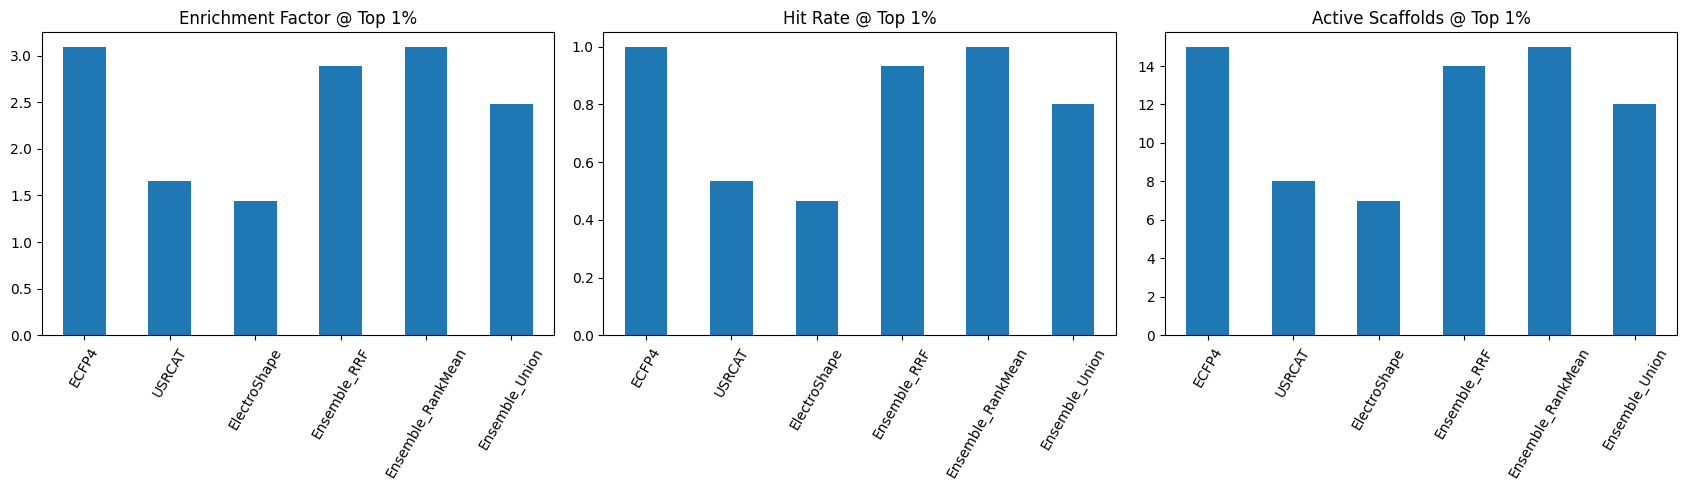

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
chart_columns = ["EF1%", "Hit Rate@1%", "Active scaffolds"]
chart_titles = ["Enrichment Factor @ Top 1%", "Hit Rate @ Top 1%", "Active Scaffolds @ Top 1%"]

for i in range(3):
    column = chart_columns[i]
    metrics[column].plot(kind="bar", ax=axes[i])
    axes[i].set_title(chart_titles[i])
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", labelrotation=60)

plt.tight_layout()
plt.show()

## 19. ROC 곡선과 AUROC

ROC 곡선은 threshold를 변화시키면서 **True Positive Rate**와 **False Positive Rate**를 보여줍니다. 하지만 실제 screening에서는 상위 소수 화합물이 중요하므로 AUROC만 보지 말고 EF1%도 함께 확인해야 합니다.

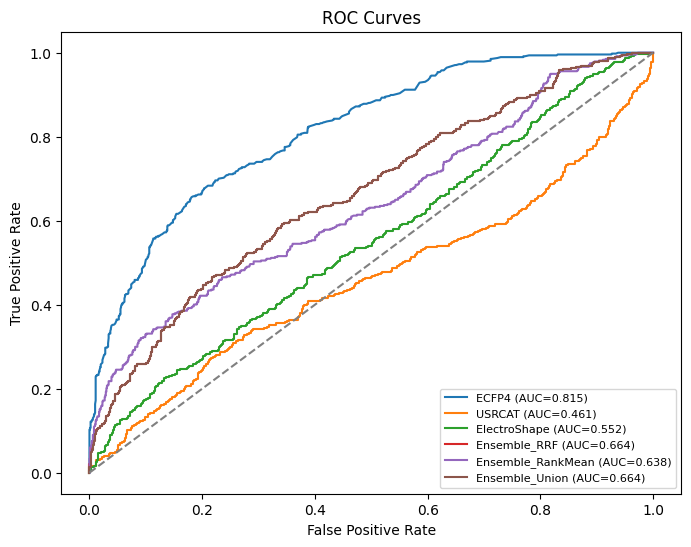

In [58]:
plt.figure(figsize=(8, 6))

for method in all_methods:
    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        results["label"], results[method]
    )
    auc_value = metrics.loc[method, "AUROC"]
    legend_text = method + " (AUC=" + str(round(auc_value, 3)) + ")"
    plt.plot(false_positive_rate, true_positive_rate, label=legend_text)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(fontsize=8)
plt.show()

## 20. 상위 몇 %를 검색할 때 Active를 얼마나 찾는가?

Top 0.5%, 1%, 2%, 5%, 10%, 20%에 따라 누적 Recall이 어떻게 변하는지 확인합니다.

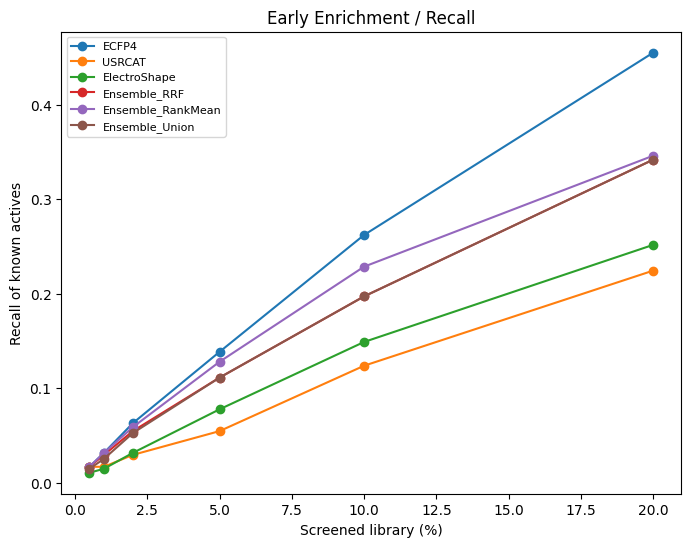

In [59]:
fractions = [0.005, 0.01, 0.02, 0.05, 0.10, 0.20]

plt.figure(figsize=(8, 6))
for method in all_methods:
    ranked = results.sort_values(method, ascending=False)
    recalls = []

    for fraction in fractions:
        top_count = max(1, int(np.ceil(len(ranked) * fraction)))
        top_compounds = ranked.head(top_count)
        active_count = int(top_compounds["label"].sum())
        recall = active_count / int(results["label"].sum())
        recalls.append(recall)

    percentages = []
    for fraction in fractions:
        percentages.append(fraction * 100)

    plt.plot(percentages, recalls, marker="o", label=method)

plt.xlabel("Screened library (%)")
plt.ylabel("Recall of known actives")
plt.title("Early Enrichment / Recall")
plt.legend(fontsize=8)
plt.show()

## 21. 방법별로 서로 다른 Active를 찾는가? (상보성)

각 방법의 Top-K에서 다른 두 방법에는 없는 **고유한 Active**가 몇 개인지 계산합니다. 고유 Active가 많으면 앙상블에 기여할 가능성이 있지만, 단순 합집합이 동일 예산에서 Hit Rate를 높인다는 뜻은 아닙니다.

In [60]:
top_sets = {}
for method in methods:
    top_rows = results.nlargest(K, method)
    top_sets[method] = set(top_rows.index)

for method in methods:
    other_indices = set()
    for other_method in methods:
        if other_method != method:
            other_indices.update(top_sets[other_method])

    unique_indices = top_sets[method] - other_indices
    unique_hits = 0
    for row_index in unique_indices:
        if results.loc[row_index, "label"] == 1:
            unique_hits += 1

    total_hits = int(results.loc[list(top_sets[method]), "label"].sum())
    print(method, ": Top-K Active =", total_hits,
          ", 다른 두 방법에 없는 Active =", unique_hits)

ECFP4 : Top-K Active = 15 , 다른 두 방법에 없는 Active = 9
USRCAT : Top-K Active = 8 , 다른 두 방법에 없는 Active = 3
ElectroShape : Top-K Active = 7 , 다른 두 방법에 없는 Active = 4


## 22. 실제 상위 후보의 화학구조 시각화

RRF 기준 상위 후보의 SMILES를 RDKit으로 그림으로 표시합니다. 라벨은 벤치마크 정답일 뿐 실험적인 검증 결과가 아닙니다.

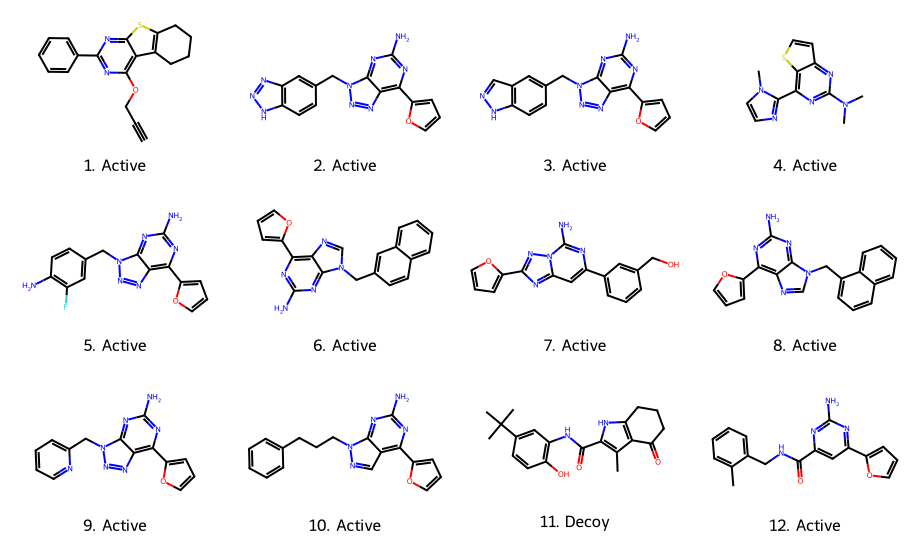

In [61]:
top_results = results.sort_values("Ensemble_RRF", ascending=False).head(12)

molecules = []
legends = []
for row_number, (_, row) in enumerate(top_results.iterrows(), start=1):
    mol = Chem.MolFromSmiles(row["smiles"])
    molecules.append(mol)

    if row["label"] == 1:
        result_text = "Active"
    else:
        result_text = "Decoy"
    legends.append(str(row_number) + ". " + result_text)

image = Draw.MolsToGridImage(molecules, molsPerRow=4,
                             subImgSize=(230, 180), legends=legends)
display(image)

## 23. '단일 방법보다 앙상블이 나은가?' 자동 비교

가장 높은 EF1%를 가진 **단일 방법**과 **앙상블**을 비교합니다. 이 결과는 **실제 노트북 실행 데이터**로 계산되며, 특정 방법이 항상 이긴다고 미리 가정하지 않습니다.

In [62]:
single_metrics = metrics.loc[methods]
ensemble_methods = ["Ensemble_RRF", "Ensemble_RankMean", "Ensemble_Union"]
ensemble_metrics = metrics.loc[ensemble_methods]

best_single = single_metrics["EF1%"].idxmax()
best_ensemble = ensemble_metrics["EF1%"].idxmax()

single_ef = metrics.loc[best_single, "EF1%"]
ensemble_ef = metrics.loc[best_ensemble, "EF1%"]

print("가장 높은 EF1%의 단일 방법:", best_single, round(single_ef, 3))
print("가장 높은 EF1%의 앙상블:", best_ensemble, round(ensemble_ef, 3))
print("앙상블 - 단일 방법 EF1% 차이:", round(ensemble_ef - single_ef, 3))

if ensemble_ef > single_ef:
    print("이번 평가에서는 앙상블의 EF1%가 더 높습니다.")
elif ensemble_ef < single_ef:
    print("이번 평가에서는 단일 방법의 EF1%가 더 높습니다.")
else:
    print("이번 평가에서는 EF1%가 같습니다.")

print("주의: 여러 조합 중 최고값을 사후 선택하면 성능이 낙관적으로 보일 수 있습니다.")

가장 높은 EF1%의 단일 방법: ECFP4 3.094
가장 높은 EF1%의 앙상블: Ensemble_RankMean 3.094
앙상블 - 단일 방법 EF1% 차이: 0.0
이번 평가에서는 EF1%가 같습니다.
주의: 여러 조합 중 최고값을 사후 선택하면 성능이 낙관적으로 보일 수 있습니다.


## 24. 결과를 CSV로 저장하고 내려받기

- `aa2ar_scores.csv`: 모든 분자의 descriptor similarity 및 앙상블 점수
- `aa2ar_metrics.csv`: 각 방법의 평가 지표
- `aa2ar_queries.csv`: 실제 검색에 사용한 Query ligand

Colab에서 다운로드하려면 맨 아래 두 줄의 주석을 해제하세요.

In [44]:
results.to_csv("aa2ar_scores.csv", index=False)
metrics.to_csv("aa2ar_metrics.csv")
queries.to_csv("aa2ar_queries.csv", index=False)

print("저장 완료: aa2ar_scores.csv / aa2ar_metrics.csv / aa2ar_queries.csv")

# Google Colab에서 즉시 내려받으려면 아래 코드를 실행합니다.
# from google.colab import files
# files.download("aa2ar_metrics.csv")

저장 완료: aa2ar_scores.csv / aa2ar_metrics.csv / aa2ar_queries.csv
